# Miniproyecto 4: Clasificación de Sonidos de la Naturaleza usando el Audio Spectrogram Transformer (AST)

## Descripción del Proyecto

Los sonidos en la naturaleza son ricos en información acústica, que se puede clasificar en diversas categorías como aves, agua, viento, entre otros. Este proyecto tiene como objetivo utilizar un modelo que pueda identificar la fuente de estos sonidos a través de un enfoque basado en transformers para transformar audio en representaciones visuales que el modelo puede analizar.

## Introducción a los Transformers

Los transformers son modelos revolucionarios en el aprendizaje profundo por su habilidad para capturar relaciones de largo alcance en datos secuenciales, como texto o audio. Originalmente desarrollados para Procesamiento de Lenguaje Natural (NLP), los transformers pueden captar relaciones complejas entre elementos secuenciales. Esto es posible gracias a su arquitectura, basada en mecanismos de auto-atención, que permite que el modelo evalúe todas las relaciones entre los elementos de una secuencia, proporcionando así un contexto completo para cada elemento en una única operación.

El Audio Spectrogram Transformer (AST) adapta esta arquitectura para datos acústicos. AST primero transforma las señales de audio en espectrogramas, representaciones visuales que exhiben cómo cambian las frecuencias en el tiempo. Al aplicar auto- atención a estos espectrogramas, el AST captura patrones acústicos detallados, permitiendo reconocer sonidos de manera robusta en distintas categorías de audio. Este enfoque es especialmente valioso en el análisis de sonidos no estructurados de la naturaleza, donde las características de los sonidos son más impredecibles y contextualmente variables.

## Objetivo

Hacer fine tuning y evaluar el modelo preentrenado Audio Spectrogram Transformer para la clasificación de sonidos naturales en categorías como “aves”, “agua”, “viento” y “mamíferos”.

## Conjunto de Datos

Se usará un dataset de grabaciones de sonido natural con diversas etiquetas de categoría llamado ESC50 que contiene 2000 grabaciones de audio para clasificación de sonidos de ambiente. Estas grabaciones se transformarán en espectrogramas para que el modelo pueda procesarlas.

## Carga de datos

Deben cargar los datos de la siguiente manera:

import torch

import torch.nn as nn

import torchaudio

from datasets import load_dataset


## Dataset de entrenamiento

dataset = load_dataset("confit/esc50-demo", "fold1", split="train")

## Dataset de test

val_dataset = load_dataset("confit/esc50-demo", "fold1", split="test")

## Modelo preentrenado

Para el modelo, deberán usar la biblioteca Transformers de Hugging Face. Pueden encontrar información sobre cómo cargar modelos, las funciones disponibles y más opciones en el siguiente enlace:

https://huggingface.co/docs/transformers/model_doc/audio-spectrogram-transformer

Les recomendamos usar el modelo "MIT/ast-finetuned-audioset-10-10-0.4593".

## Actividades por Realizar

1. Procesamiento de Audio: Diseñar un pipeline que convierta cada archivo de audio en espectrogramas visuales, normalizando los datos y garantizando consistencia en los tamaños de entrada. Los espectrogramas generados deben estar listos para ser usados como entradas para el modelo AST.

2. Implementación del Audio Spectrogram Transformer: Hacer fine tuning de un modelo de AST durante 2 épocas para adaptarlo a la tarea específica.

3. Evaluación del Modelo: Realizar predicciones sobre los datos y reportar métricas como precisión, recall y F1-score, además de un análisis detallado de las categorías en las que el modelo presenta mejor o peor rendimiento. La evaluación también incluirá un análisis de la matriz de confusión para observar los patrones de errores y las categorías más confusas para el modelo.

### Importación de librerias necesarias

In [1]:
import torch
print("Versión de PyTorch:", torch.__version__)

Versión de PyTorch: 2.1.2+cu121


In [2]:
pip install torchaudio==2.1.2+cu121 --index-url https://download.pytorch.org/whl/cu121 --force-reinstall

Looking in indexes: https://download.pytorch.org/whl/cu121
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 88.1 MB/s eta 0:00:00:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 GB 1.6 MB/s eta 0:00:000:00:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.2/89.2 MB 37.5 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 23.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.9/134.9 kB 65.2 MB/s eta 0:00:00
Using cached networkx-3.1-py3-none-any.whl (2.1 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.2/6.2 MB 70.0 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.8/45.8 kB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.2/536.2 kB 123.4 MB/s eta 0:00:00
  Attempting uninstall: mpmath
    Found existing installation: mpmath 1.3.0
    Uninstalling mpmath-1.3.0:
      Successfully uninstalled mpmath-1.3.0
  Attempting uninstall: typing-extensions
    Found existing in

In [3]:
!pip install librosa soundfile

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 260.7/260.7 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 55.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 413.8/413.8 kB 95.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 134.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.6/64.6 kB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 117.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 MB 53.3 MB/s eta 0:00:00:00:0100:01

[notice] A new release of pip is available: 23.3.2 -> 25.0.1
[notice] To update, run: python -m pip install --upgrade pip


In [33]:
import numpy as np
import random
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score, accuracy_score, classification_report
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchaudio
from datasets import load_dataset
from datasets import Audio as DatasetAudio
from transformers import AutoFeatureExtractor, AutoModelForAudioClassification, TrainingArguments, Trainer
from collections import Counter
from IPython.display import Audio, display

In [5]:
SEED = 42

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Algoritmos deterministas para que cada ejecución entregue los mismos resultados
torch.use_deterministic_algorithms(False)
seed_everything(SEED)

### Dispositivo de computo

In [6]:
if torch.cuda.is_available():
    print("Nombre de la GPU:", torch.cuda.get_device_name(0))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Usando dispositivo: {device}')

Nombre de la GPU: NVIDIA L4
Usando dispositivo: cuda


## Carga de datos

In [7]:
# Dataset de entrenamiento
dataset = load_dataset("confit/esc50-demo", "fold1", split="train")

Generating train split:   0%|          | 0/1600 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/400 [00:00<?, ? examples/s]

In [8]:
# Dataset de test
test_dataset = load_dataset("confit/esc50-demo", "fold1", split="test")

In [21]:
# Dividimos el dataset de entrenamiento en los conjuntos de entrenamiento (80%) y validación (20%).
splits = dataset.train_test_split(test_size=0.2, seed=42, stratify_by_column="label")
train_ds = splits['train']
val_ds = splits['test']

**Imprimimos cuántos datos tenemos por conjunto:**

In [22]:
train_ds

Dataset({
    features: ['audio', 'sound', 'label'],
    num_rows: 1280
})

In [23]:
val_ds

Dataset({
    features: ['audio', 'sound', 'label'],
    num_rows: 320
})

In [24]:
test_dataset

Dataset({
    features: ['audio', 'sound', 'label'],
    num_rows: 400
})

En resumen tenemos: 

1280 registros de audio para entrenamiento, 320 para validación y 400 para prueba.

Las features (características o columnas) definen las llaves (keys) que contiene cada diccionario de muestra dentro del dataset. Cada ejemplo individual dentro del dataset respectivo almacena tres piezas clave de información:

'audio': Es un diccionario automatizado por Hugging Face que almacena la información técnica del archivo de sonido. Típicamente incluye la ruta al archivo (path), el arreglo numérico con la onda de audio cruda (array) y la tasa de muestreo (sampling rate, usualmente 16,000 Hz).

'sound': Es una etiqueta o descripción textual en formato de texto plano que nombra la categoría del sonido ambiental de la naturaleza o la ciudad (por ejemplo, "chirping_birds", "wind", "rain", etc.).

'label': Es el identificador numérico (entero) asociado a esa categoría de sonido.

In [25]:
#Vemos las etiquetas
train_ds.features

{'audio': Audio(sampling_rate=44100, mono=True, decode=True, id=None),
 'sound': Value(dtype='string', id=None),
 'label': ClassLabel(names=['airplane', 'breathing', 'brushing_teeth', 'can_opening', 'car_horn', 'cat', 'chainsaw', 'chirping_birds', 'church_bells', 'clapping', 'clock_alarm', 'clock_tick', 'coughing', 'cow', 'crackling_fire', 'crickets', 'crow', 'crying_baby', 'dog', 'door_wood_creaks', 'door_wood_knock', 'drinking_sipping', 'engine', 'fireworks', 'footsteps', 'frog', 'glass_breaking', 'hand_saw', 'helicopter', 'hen', 'insects', 'keyboard_typing', 'laughing', 'mouse_click', 'pig', 'pouring_water', 'rain', 'rooster', 'sea_waves', 'sheep', 'siren', 'sneezing', 'snoring', 'thunderstorm', 'toilet_flush', 'train', 'vacuum_cleaner', 'washing_machine', 'water_drops', 'wind'], id=None)}

De lo anterior se observa que los audios originales están a 44.1 kHz, pero el modelo AST requiere obligatoriamente una tasa de muestreo de 16,000 Hz (16 kHz), por lo tanto en la función de pre-procesamiento se debe hacer un remuestreo para bajar la tasa de los audios de 44.1 kHz a 16 kHz usando las herramientas de re-muestreo integradas en Hugging Face.

### Número de clases:

In [26]:
train_ds.features["label"]

ClassLabel(names=['airplane', 'breathing', 'brushing_teeth', 'can_opening', 'car_horn', 'cat', 'chainsaw', 'chirping_birds', 'church_bells', 'clapping', 'clock_alarm', 'clock_tick', 'coughing', 'cow', 'crackling_fire', 'crickets', 'crow', 'crying_baby', 'dog', 'door_wood_creaks', 'door_wood_knock', 'drinking_sipping', 'engine', 'fireworks', 'footsteps', 'frog', 'glass_breaking', 'hand_saw', 'helicopter', 'hen', 'insects', 'keyboard_typing', 'laughing', 'mouse_click', 'pig', 'pouring_water', 'rain', 'rooster', 'sea_waves', 'sheep', 'siren', 'sneezing', 'snoring', 'thunderstorm', 'toilet_flush', 'train', 'vacuum_cleaner', 'washing_machine', 'water_drops', 'wind'], id=None)

In [27]:
num_labels = train_ds.features["label"].num_classes
print(f"Número de clases: {num_labels}")

Número de clases: 50


**Identificación de etiquetas e índices de clases:**

In [28]:
id2label = {id:label for id, label in enumerate(train_ds.features['label'].names)}
label2id = {label:id for id,label in id2label.items()}
id2label

{0: 'airplane',
 1: 'breathing',
 2: 'brushing_teeth',
 3: 'can_opening',
 4: 'car_horn',
 5: 'cat',
 6: 'chainsaw',
 7: 'chirping_birds',
 8: 'church_bells',
 9: 'clapping',
 10: 'clock_alarm',
 11: 'clock_tick',
 12: 'coughing',
 13: 'cow',
 14: 'crackling_fire',
 15: 'crickets',
 16: 'crow',
 17: 'crying_baby',
 18: 'dog',
 19: 'door_wood_creaks',
 20: 'door_wood_knock',
 21: 'drinking_sipping',
 22: 'engine',
 23: 'fireworks',
 24: 'footsteps',
 25: 'frog',
 26: 'glass_breaking',
 27: 'hand_saw',
 28: 'helicopter',
 29: 'hen',
 30: 'insects',
 31: 'keyboard_typing',
 32: 'laughing',
 33: 'mouse_click',
 34: 'pig',
 35: 'pouring_water',
 36: 'rain',
 37: 'rooster',
 38: 'sea_waves',
 39: 'sheep',
 40: 'siren',
 41: 'sneezing',
 42: 'snoring',
 43: 'thunderstorm',
 44: 'toilet_flush',
 45: 'train',
 46: 'vacuum_cleaner',
 47: 'washing_machine',
 48: 'water_drops',
 49: 'wind'}

De lo anterior se observa que se tienen 50 clases de sonido.

### Verificación balanceo de clases:

In [29]:
# Obtenemos la lista de nombres de las 50 clases
label_names = train_ds.features["label"].names

# Contamos las apariciones de cada índice en los tres splits
train_counts = Counter(train_ds["label"])
val_counts = Counter(val_ds["label"])
test_counts = Counter(test_dataset["label"])

# Construimos un DataFrame consolidado para inspeccionarlo
df_dist = pd.DataFrame({
    "Clase": label_names,
    "Train": [train_counts[i] for i in range(len(label_names))],
    "Validation": [val_counts[i] for i in range(len(label_names))],
    "Test": [test_counts[i] for i in range(len(label_names))],
})

df_dist["Total"] = df_dist["Train"] + df_dist["Validation"] + df_dist["Test"]

# Mostramos el resumen estadístico (mínimo, máximo y promedio por columna)
print(df_dist.describe())

# Mostramos las primeras 15 filas para inspección visual
print("\nMuestra por clase:")
print(df_dist.head(15).to_string(index=False))

           Train  Validation  Test  Total
count  50.000000   50.000000  50.0   50.0
mean   25.600000    6.400000   8.0   40.0
std     0.494872    0.494872   0.0    0.0
min    25.000000    6.000000   8.0   40.0
25%    25.000000    6.000000   8.0   40.0
50%    26.000000    6.000000   8.0   40.0
75%    26.000000    7.000000   8.0   40.0
max    26.000000    7.000000   8.0   40.0

Muestra por clase:
         Clase  Train  Validation  Test  Total
      airplane     25           7     8     40
     breathing     26           6     8     40
brushing_teeth     26           6     8     40
   can_opening     25           7     8     40
      car_horn     26           6     8     40
           cat     26           6     8     40
      chainsaw     25           7     8     40
chirping_birds     26           6     8     40
  church_bells     25           7     8     40
      clapping     25           7     8     40
   clock_alarm     26           6     8     40
    clock_tick     25           7     

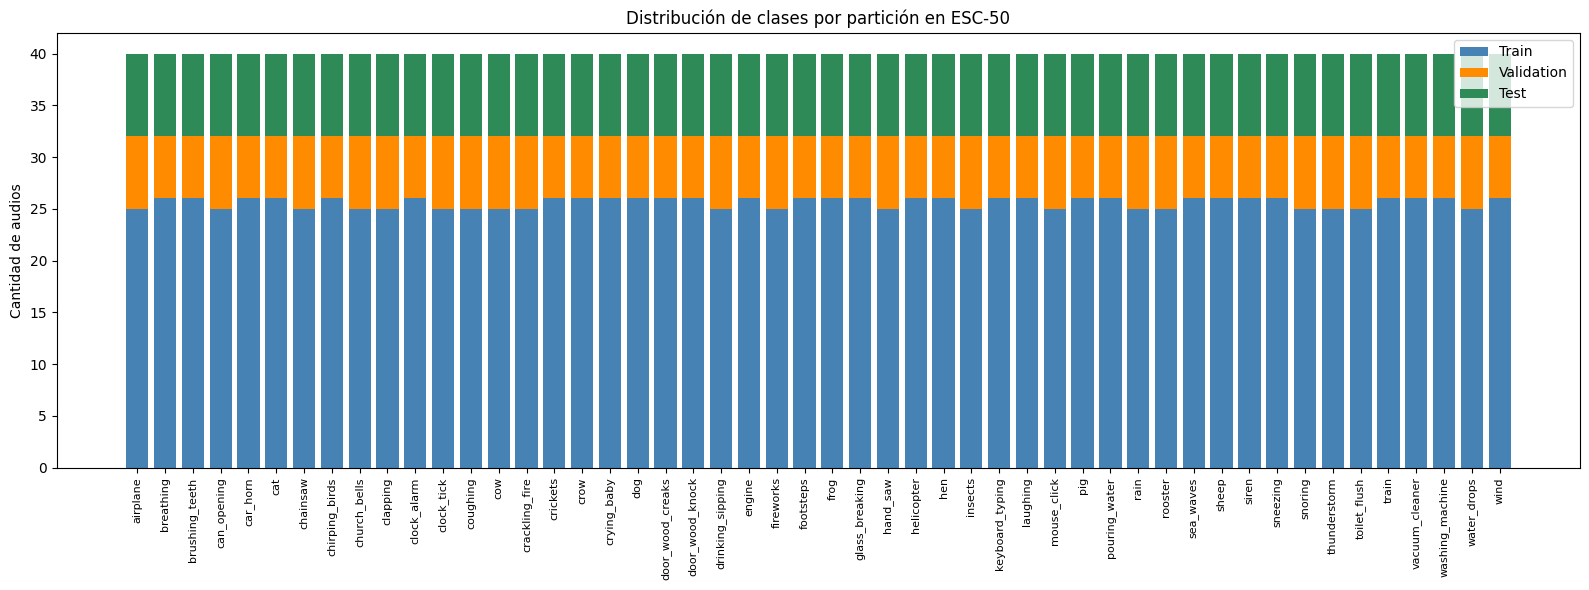

In [30]:
fig, ax = plt.subplots(figsize=(16, 6))

# Graficamos el conteo por conjunto de datos
ax.bar(df_dist["Clase"], df_dist["Train"], color="steelblue", label="Train")
ax.bar(
    df_dist["Clase"],
    df_dist["Validation"],
    bottom=df_dist["Train"],
    color="darkorange",
    label="Validation",
)
ax.bar(
    df_dist["Clase"],
    df_dist["Test"],
    bottom=df_dist["Train"] + df_dist["Validation"],
    color="seagreen",
    label="Test",
)

plt.xticks(rotation=90, fontsize=8)
plt.ylabel("Cantidad de audios")
plt.title("Distribución de clases por partición en ESC-50")
plt.legend()
plt.tight_layout()
plt.show()

**De lo anterior se obser que no hay desbalanceo de clases**

## Pipeline de procesamiento de audio

Diseñar un pipeline que convierta cada archivo de audio en espectrogramas visuales, normalizando los datos y garantizando consistencia en los tamaños de entrada. Los espectrogramas generados deben estar listos para ser usados como entradas para el modelo AST. Referencia: https://huggingface.co/papers/2104.01778, https://arxiv.org/abs/2104.01778


Esto se realiza mediante un extractor de características de Transformers, que normaliza las entradas y las convierte al formato que el modelo espera, además de generar las demás entradas que el modelo requiere. Podemos preparar el audio usando AutoFeatureExtractor, que lo convierte en un tensor de espectrograma con forma (tamaño_lote, dimensión_tiempo, dimensión_frecuencia). El extractor de características también se encarga de la normalización usando la media y la desviación estándar del conjunto de datos AudioSet. Para ello, instanciamos nuestro extractor de características con el método `AutoFeatureExtractor.from_pretrained`, lo que garantiza que obtendremos un preprocesador que se corresponda con la arquitectura del modelo que queremos utilizar: "MIT/ast-finetuned-audioset-10-10-0.4593". Referencias: https://huggingface.co/docs/transformers/model_doc/audio-spectrogram-transformer, https://huggingface.co/docs/transformers/v5.23.0/en/model_doc/audio-spectrogram-transformer#transformers.ASTFeatureExtractor

https://colab.research.google.com/github/huggingface/notebooks/blob/main/examples/audio_classification.ipynb#scrollTo=niniUAnb5IrR

### Inicializar FeatureExtractor con modelo pre-entrenado "MIT/ast-finetuned-audioset-10-10-0.4593"

In [31]:
model_id = "MIT/ast-finetuned-audioset-10-10-0.4593"
feature_extractor = AutoFeatureExtractor.from_pretrained(model_id)

### Sincronizar la Tasa de Muestreo (Resampling a 16 kHz)

In [34]:
# Forzamos a que el dataset convierta automáticamente los audios a 16,000 Hz al cargarlos
train_ds = train_ds.cast_column("audio", DatasetAudio(sampling_rate=16000))
val_ds = val_ds.cast_column("audio", DatasetAudio(sampling_rate=16000))
test_dataset = test_dataset.cast_column("audio", DatasetAudio(sampling_rate=16000))

### Función de preprocesamiento

A continuación, construimos la función que preprocesará los audios utilizando feature_extractor.

In [35]:
def preprocess_function(examples):
    # Extraemos el arreglo numérico de cada onda de audio
    audio_arrays = [x["array"] for x in examples["audio"]]
    
    # El feature_extractor convierte el audio en espectrograma mel (las "matrices visuales" de frecuencia y tiempo), 
    # normaliza los datos y aplica padding/truncamiento para asegurar consistencia en el tamaño
    inputs = feature_extractor(
        audio_arrays,
        sampling_rate=16000,
        padding="max_length",  # Rellena o recorta para que todos midan exacto en el tiempo
        return_tensors="pt"
    )
    
    # Asignamos las etiquetas correspondientes para el entrenamiento supervisado
    inputs["labels"] = examples["label"]
    return inputs

### Aplicar el Pipeline a cada dataser (.map)

In [36]:
# Mapeamos el conjunto de entrenamiento
encoded_train_ds = train_ds.map(
    preprocess_function,
    batched=True,
    remove_columns=train_ds.column_names # Eliminamos columnas originales para dejar solo los tensores limpios
)

# Mapeamos el conjunto de validación interna
encoded_val_ds = val_ds.map(
    preprocess_function,
    batched=True,
    remove_columns=val_ds.column_names
)

# Mapeamos el conjunto de prueba final
encoded_test_ds = test_dataset.map(
    preprocess_function,
    batched=True,
    remove_columns=test_dataset.column_names
)

Map:   0%|          | 0/1280 [00:00<?, ? examples/s]

Map:   0%|          | 0/320 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

## Impelementación del Audio Spectogram Transformer

Para la clasificación, utilizamos la clase AutoModelForAudioClassification. Al igual que con el extractor de características, el método from_pretrained descargará y almacenará en caché el modelo. Como los identificadores de etiquetas y el número de etiquetas dependen del conjunto de datos, pasamos num_labels, label2id e id2label junto con model_id. Referencias: https://huggingface.co/docs/transformers/v5.23.0/en/model_doc/audio-spectrogram-transformer#transformers.ASTForAudioClassification

A continuación instanciamos el modelo AST:

In [38]:
model = AutoModelForAudioClassification.from_pretrained(
    model_id, 
    num_labels=num_labels,
    label2id=label2id,
    id2label=id2label,
    ignore_mismatched_sizes=True
)

Some weights of ASTForAudioClassification were not initialized from the model checkpoint at MIT/ast-finetuned-audioset-10-10-0.4593 and are newly initialized because the shapes did not match:
- classifier.dense.bias: found shape torch.Size([527]) in the checkpoint and torch.Size([50]) in the model instantiated
- classifier.dense.weight: found shape torch.Size([527, 768]) in the checkpoint and torch.Size([50, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


## Entrenamiento del modelo

In [39]:
model_name = "ast-finetuned-esc50"
batch_size_train = 4
batch_size_val = 2
# Definimos el nombre de la métrica que utilizaremos para el entrenamiento, en este caso, "accuracy"
metric_name = "accuracy"

# Configuramos los argumentos de entrenamiento mediante la instancia de TrainingArguments
args = TrainingArguments(
    model_name,
    evaluation_strategy = "epoch",
    save_strategy = "epoch",
    learning_rate=3e-5,
    per_device_train_batch_size=batch_size_train,
    gradient_accumulation_steps=8,
    per_device_eval_batch_size=batch_size_val,
    num_train_epochs=2,
    warmup_ratio=0.1,
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model=metric_name,
    push_to_hub=False,
    logging_dir='logs',
    remove_unused_columns=False,
)

### Métrica de entrenamiento

In [40]:
# Definimos una función para calcular métricas a partir de las predicciones de evaluación
def compute_metrics(eval_pred):
    # Desempaquetamos las predicciones y las etiquetas verdaderas del objeto eval_pred
    predictions, labels = eval_pred

    # Convertimos las predicciones en etiquetas predichas tomando el índice del valor máximo en cada fila. Es decir, escogemos la clase con la más alta probabilidad.
    predictions = np.argmax(predictions, axis=1)

    # Calculamos la precisión comparando las etiquetas predichas con las etiquetas verdaderas
    return dict(accuracy=accuracy_score(predictions, labels))


Pasamos todos estos parámetros junto con nuestros conjuntos de datos al Trainer:

In [41]:
trainer = Trainer(
    model,
    args,
    train_dataset=encoded_train_ds,
    eval_dataset=encoded_val_ds,
    tokenizer=feature_extractor,
    compute_metrics=compute_metrics
)

Ahora podemos hacer finetuning a nuestro modelo simplemente llamando al método train

In [42]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,1.028800,0.749954,0.896875
2,0.253100,0.344350,0.962500


Checkpoint destination directory ast-finetuned-esc50/checkpoint-40 already exists and is non-empty. Saving will proceed but saved results may be invalid.
Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-default generation parameters: {'max_length': 1024}
Checkpoint destination directory ast-finetuned-esc50/checkpoint-80 already exists and is non-empty. Saving will proceed but saved results may be invalid.
Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-default generation parameters: {'max_length': 1024}


TrainOutput(global_step=80, training_loss=1.3129537016153336, metrics={'train_runtime': 567.6321, 'train_samples_per_second': 4.51, 'train_steps_per_second': 0.141, 'total_flos': 1.7359838380032e+17, 'train_loss': 1.3129537016153336, 'epoch': 2.0})

In [43]:
metrics_val = trainer.evaluate()
print(metrics_val)

{'eval_loss': 0.3443496823310852, 'eval_accuracy': 0.9625, 'eval_runtime': 29.3918, 'eval_samples_per_second': 10.887, 'eval_steps_per_second': 5.444, 'epoch': 2.0}


## Evaluación del modelo y matriz de confusión

Finalmente, evaluemos el desempeño del modelo en el conjunto de prueba:

In [44]:
test_metrics = trainer.evaluate(eval_dataset=encoded_test_ds)
print(test_metrics)

{'eval_loss': 0.4378526210784912, 'eval_accuracy': 0.93, 'eval_runtime': 36.9887, 'eval_samples_per_second': 10.814, 'eval_steps_per_second': 5.407, 'epoch': 2.0}


In [45]:
outputs = trainer.predict(encoded_test_ds)

In [46]:
print(outputs.metrics)

{'test_loss': 0.4378526210784912, 'test_accuracy': 0.93, 'test_runtime': 36.3163, 'test_samples_per_second': 11.014, 'test_steps_per_second': 5.507}


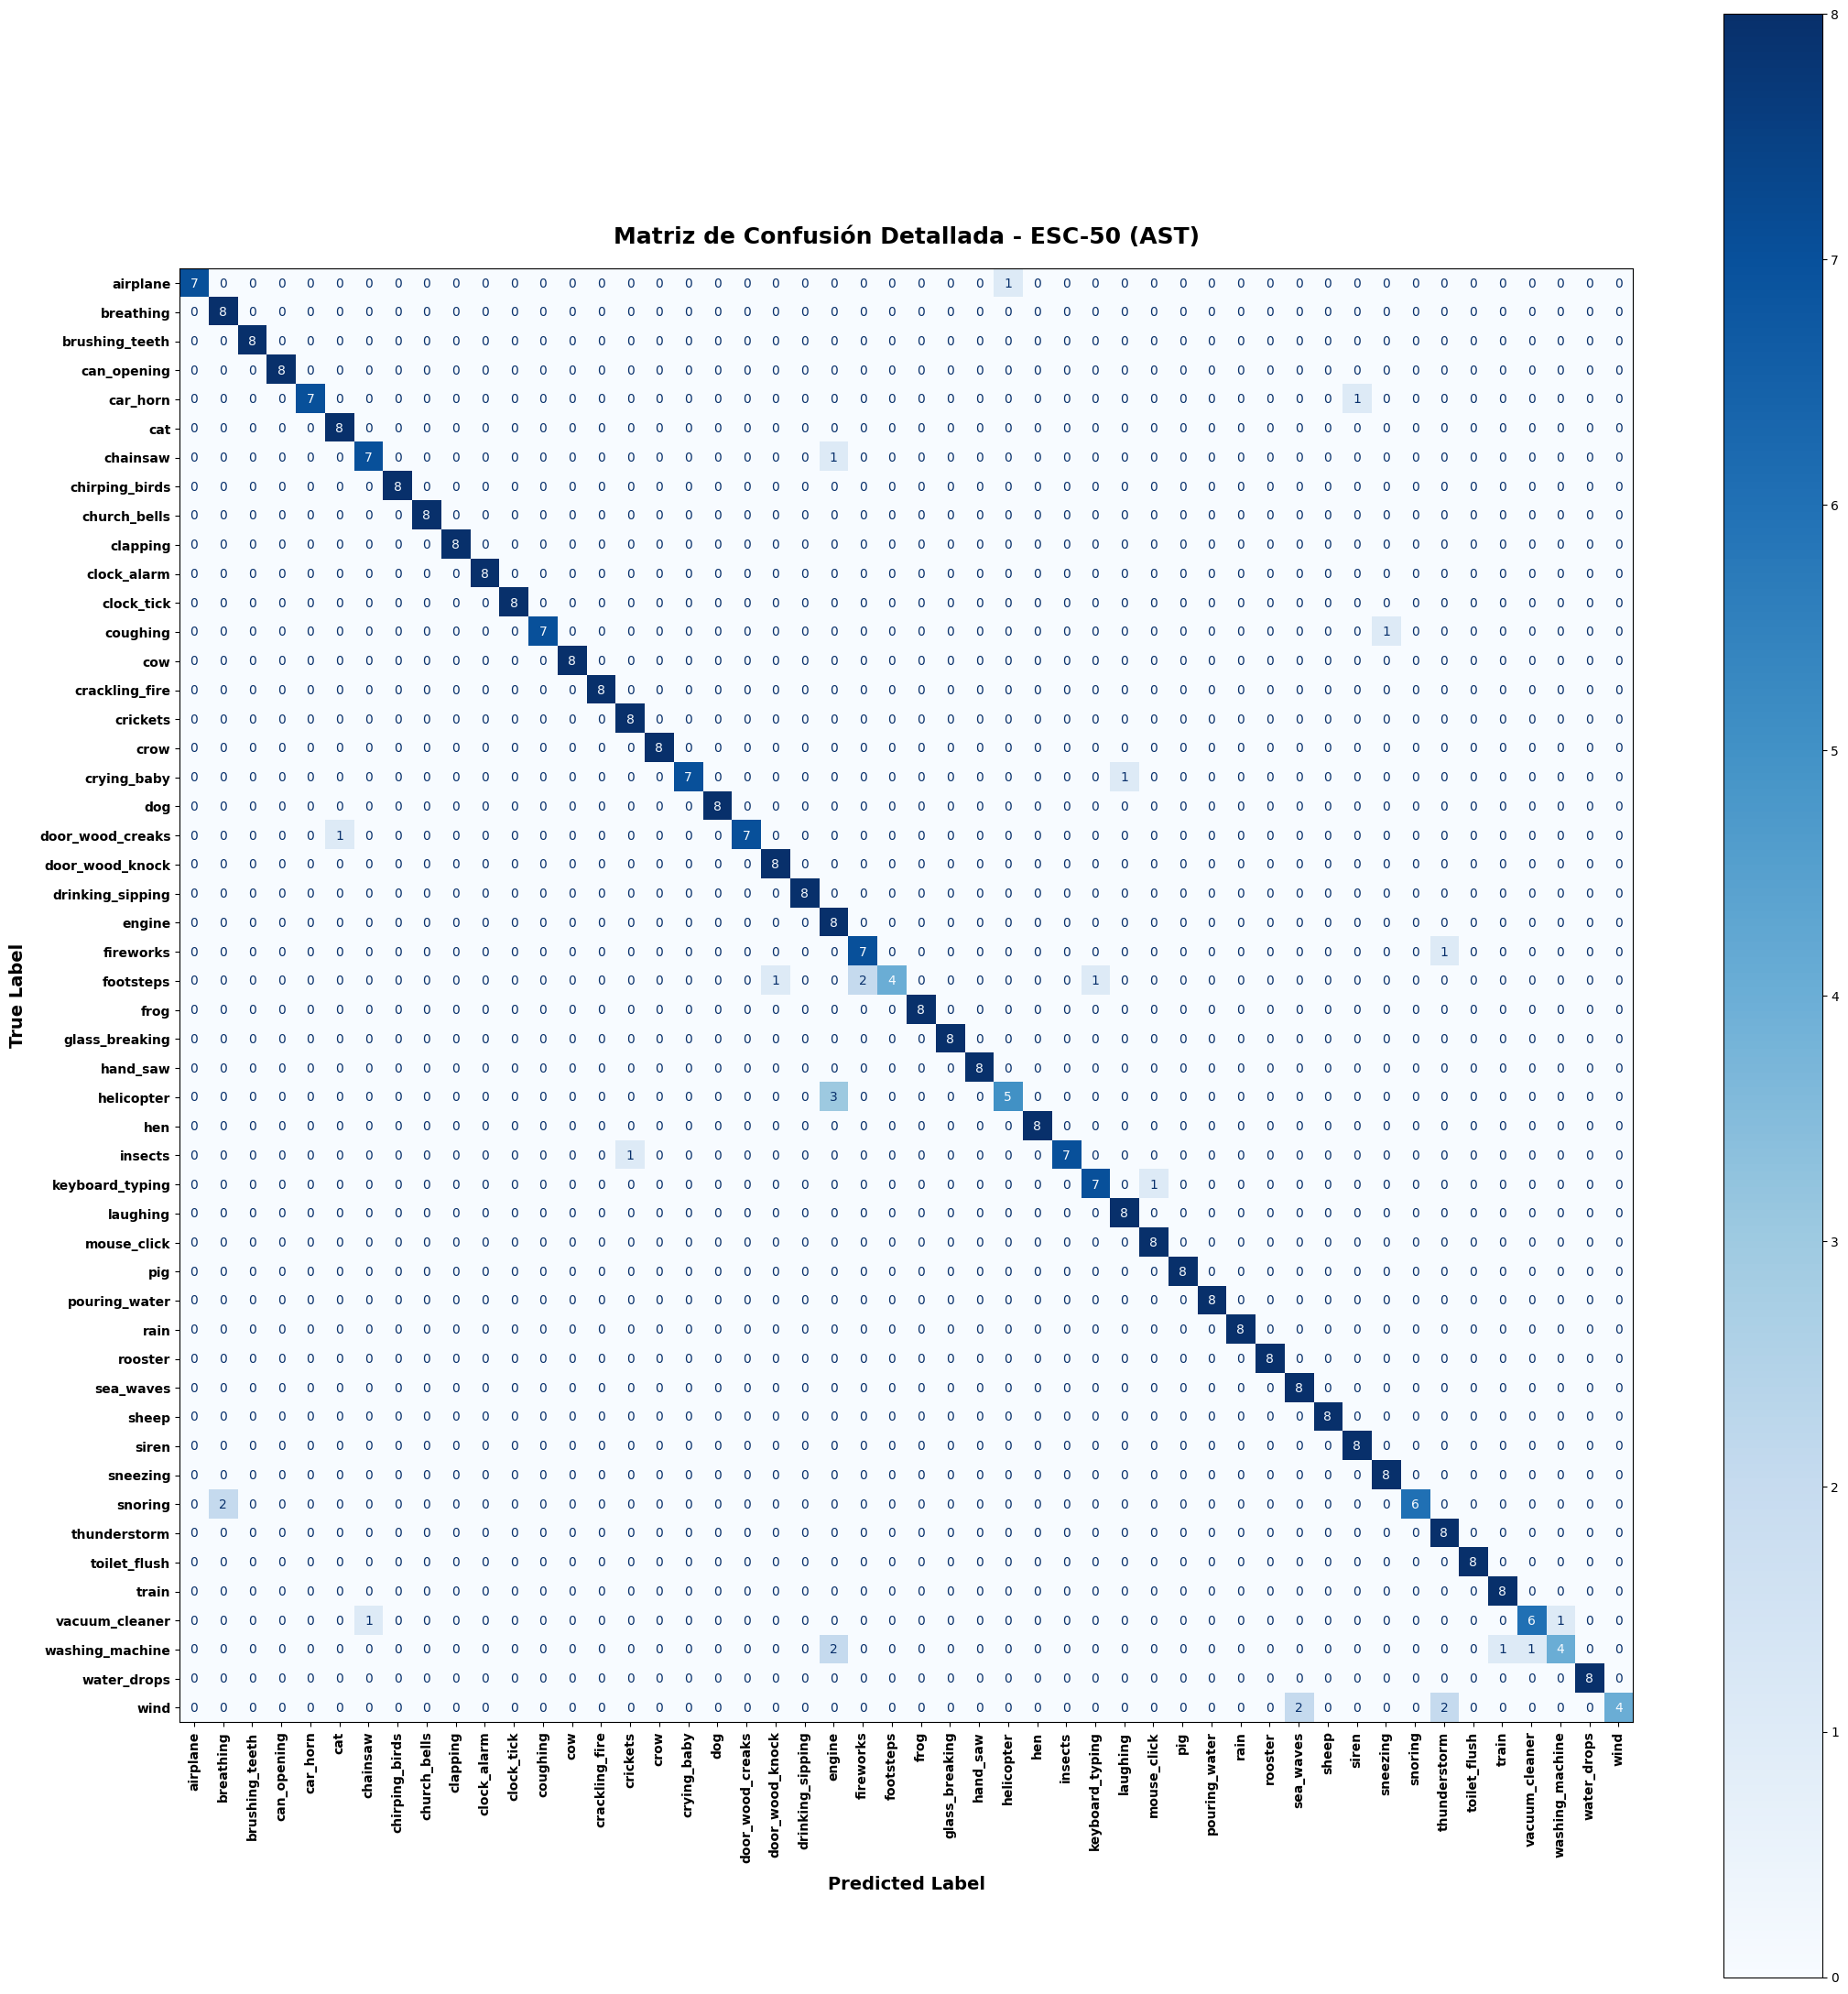

In [47]:
# Obtenemos las etiquetas reales y predichas del conjunto de datos de evaluación
y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(1)

# Obtenemos las etiquetas disponibles en el conjunto de datos
labels = train_ds.features['label'].names

# Calculamos la matriz de confusión
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(22, 22))

# Generamos el display con rotación vertical de 90° en el eje X para evitar cruces
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(
    ax=ax,
    xticks_rotation=90,  # Rotación completa vertical
    cmap="Blues",
    colorbar=True,
    values_format="d",
)

# Ajustes de tipografía y títulos
plt.xticks(fontsize=10, fontweight="bold")
plt.yticks(fontsize=10, fontweight="bold")
plt.xlabel("Predicted Label", fontsize=14, fontweight="bold", labelpad=10)
plt.ylabel("True Label", fontsize=14, fontweight="bold", labelpad=10)
plt.title(
    "Matriz de Confusión Detallada - ESC-50 (AST)",
    fontsize=18,
    fontweight="bold",
    pad=20,
)

# Guardar en alta resolución antes de mostrarla
plt.savefig(
    "matriz_confusion_alta_resolucion.png", dpi=300, bbox_inches="tight"
)

plt.tight_layout()
plt.show()

### Reporte detallado por clase (Precision, Recall, F1-score)

In [48]:
print(classification_report(y_true, y_pred, target_names=train_ds.features["label"].names))

                  precision    recall  f1-score   support

        airplane       1.00      0.88      0.93         8
       breathing       0.80      1.00      0.89         8
  brushing_teeth       1.00      1.00      1.00         8
     can_opening       1.00      1.00      1.00         8
        car_horn       1.00      0.88      0.93         8
             cat       0.89      1.00      0.94         8
        chainsaw       0.88      0.88      0.88         8
  chirping_birds       1.00      1.00      1.00         8
    church_bells       1.00      1.00      1.00         8
        clapping       1.00      1.00      1.00         8
     clock_alarm       1.00      1.00      1.00         8
      clock_tick       1.00      1.00      1.00         8
        coughing       1.00      0.88      0.93         8
             cow       1.00      1.00      1.00         8
  crackling_fire       1.00      1.00      1.00         8
        crickets       0.89      1.00      0.94         8
            c

## Análisis de resultados

A partir del reporte de clasificación y la matriz de confusión proporcionados, se pueden extraer las siguientes conclusiones:

1. Conclusiones Generales
Desempeño Sobresaliente: El modelo alcanzó una exactitud global (accuracy) del 93% (372 aciertos de 400 muestras totales), con un promedio ponderado (weighted avg) y macro (macro avg) de F1-score de 0.93. Esto demuestra que la estrategia de preprocesamiento, el re-muestreo a 16 kHz y la adaptación de pesos mediante ignore_mismatched_sizes=True fueron sumamente exitosos.   


2. Categorías con Mejor Rendimiento
Un gran número de clases (24 clases) lograron una puntuación perfecta de 1.00 en F1-score (Precision y Recall del 100%), lo que significa que los 8 audios de prueba de cada una de estas categorías fueron clasificados a la perfección sin un solo error. Entre ellas destacan:   


Sonidos de animales y naturaleza: dog, frog, rooster, chirping_birds, rain, cow, crickets, crow, hen, sheep, water_drops.   


Sonidos urbanos y domésticos/efectos: glass_breaking, brushing_teeth, can_opening, church_bells, clapping, clock_alarm, clock_tick, crackling_fire, hand_saw, pig, pouring_water, siren, toilet_flush.   


3. Categorías con Menor Rendimiento
Las categorías que presentaron mayores dificultades para el modelo y obtuvieron las métricas más bajas son:   


washing_machine (F1: 0.62 | Precision: 0.80, Recall: 0.50): Su precisión de 0.80, significa que cuando predice lavadora suele acertar, pero deja de indetificar la mitad de los ejemplos reales.

footsteps (F1: 0.67 | Precision: 1.00, Recall: 0.50) y wind (F1: 0.67 | Precision: 1.00, Recall: 0.50): Ambas alcanzan una precisión perfecta del 100% (no generan falsos positivos en otras clases), pero presentan una sensibilidad baja (4 aciertos de 8).

helicopter (F1: 0.71 | Precision: 0.83, Recall: 0.62) y engine (F1: 0.73 | Precision: 0.57, Recall: 1.00): engine detecta el 100% de sus propios audios (8/8), pero su precisión es baja (0.57) porque actúa como un "atractor" para otros sonidos mecánicos.

4. Patrones de Errores Principales (Matriz de Confusión)

Al analizar la matriz de confusión, los errores del modelo responden a similitudes físicas y acústicas:   

4.1 El efecto "atractor" de engine (Maquinaria y Motores):

engine absorbe falsos positivos de helicopter (3 veces), washing_machine (2 veces) y chainsaw (1 vez).   


Asimismo, washing_machine se confunde con train (1 vez) y vacuum_cleaner (1 vez), mientras que vacuum_cleaner se confunde con washing_machine (1 vez) y chainsaw (1 vez). Todos comparten armónicos de baja frecuencia y vibraciones constantes.   


4.2 Ruido Atmosférico de Banda Ancha (wind):

Las 4 muestras fallidas de wind se reparten equitativamente entre sea_waves (2 veces) y thunderstorm (2 veces), debido a la similitud en la distribución de energía a través del espectro de frecuencias (ruido ambiental continuo).   


4.3 Eventos Impulsivos y de Fricción (footsteps):

Los 4 errores de footsteps se dispersan hacia fireworks (2 veces), door_wood_knock (1 vez) e insects (1 vez), reflejando la dificultad de aislar pisadas breves frente a otros impactos secos o crujidos ambientales.   


4.4 Sonidos Humanos Respiratorios (snoring vs. breathing):

Se observa un patrón específico donde snoring (ronquidos) se confunde 2 veces con breathing (respiración) (reduciendo la precisión de breathing a 0.80), lo cual es completamente natural dado que ambos comparten la misma fisiología y cadencia temporal.   


## Análisis cualitativo

A continuación se implementa función para inspeccionar muestras individuales del conjunto de test.

In [52]:
def analisis_cualitativo(indice, raw_ds, encoded_ds, outputs, id2label):
    """Inspecciona una muestra individual mostrando probabilidades Top-3,

    reproductor de audio y su espectrograma de Mel procesado.
    """
    indice = int(indice)  # <--- Convierte numpy.int64 a int nativo de Python
    # 1. Extraer datos crudos y procesados
    audio_data = raw_ds[indice]["audio"]
    array_audio = audio_data["array"]
    sr = audio_data["sampling_rate"]
    espectrograma = encoded_ds[indice]["input_values"]

    # 2. Calcular probabilidades mediante Softmax sobre los logits
    logits = torch.tensor(outputs.predictions[indice])
    probs = torch.nn.functional.softmax(logits, dim=-1).numpy()

    # 3. Obtener el Top-3 de predicciones
    top3_idx = np.argsort(probs)[::-1][:3]
    etiqueta_real = id2label[outputs.label_ids[indice]]
    etiqueta_pred = id2label[top3_idx[0]]

    # 4. Imprimir resumen de diagnóstico
    estado = "✅ ACIERTO" if etiqueta_real == etiqueta_pred else "❌ ERROR"
    print(f"==================================================")
    print(f"Muestra #{indice} | Estado: {estado}")
    print(f"Etiqueta Real:     {etiqueta_real}")
    print(
        f"Predicción Modelo: {etiqueta_pred} ({probs[top3_idx[0]]*100:.2f}%)"
    )
    print(f"--------------------------------------------------")
    print("Top 3 Probabilidades:")
    for rank, idx in enumerate(top3_idx, 1):
        print(f"  {rank}. {id2label[idx]:<20} -> {probs[idx]*100:.2f}%")
    print(f"==================================================")

    # 5. Reproductor de audio interactivo en Jupyter
    display(Audio(data=array_audio, rate=sr))

    # 6. Visualizar el espectrograma exacto que recibió el AST
    plt.figure(figsize=(10, 4))
    # Transponemos (.T) para que el tiempo quede en el eje X y la frecuencia en el eje Y
    plt.imshow(
        np.array(espectrograma).T,
        aspect="auto",
        origin="lower",
        cmap="magma",
    )
    plt.colorbar(format="%+2.0f dB")
    plt.title(
        f"Espectrograma Mel - Real: '{etiqueta_real}' vs Pred: '{etiqueta_pred}'"
    )
    plt.xlabel("Pasos de tiempo (Frames)")
    plt.ylabel("Bandas Mel (Frecuencia)")
    plt.tight_layout()
    plt.show()

Total de errores encontrados: 28 de 400
Primeros 10 índices con error: [ 41  44  54  61  88  89  96 105 132 141]
Muestra #41 | Estado: ❌ ERROR
Etiqueta Real:     snoring
Predicción Modelo: breathing (27.67%)
--------------------------------------------------
Top 3 Probabilidades:
  1. breathing            -> 27.67%
  2. snoring              -> 16.84%
  3. crying_baby          -> 11.89%


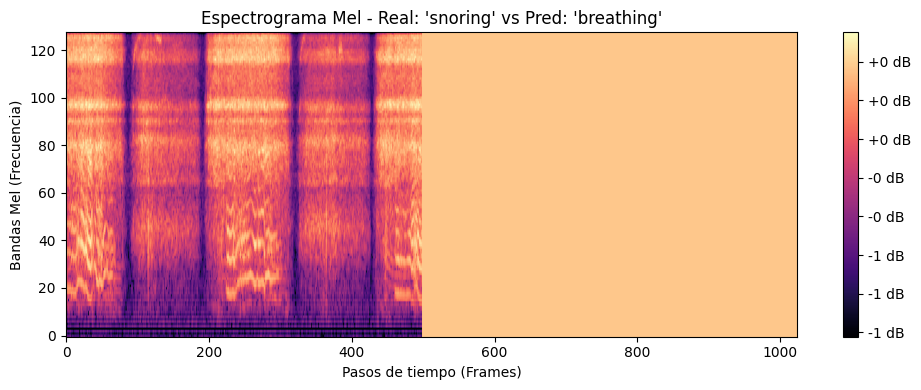

Muestra #44 | Estado: ❌ ERROR
Etiqueta Real:     helicopter
Predicción Modelo: engine (25.34%)
--------------------------------------------------
Top 3 Probabilidades:
  1. engine               -> 25.34%
  2. helicopter           -> 24.25%
  3. airplane             -> 5.51%


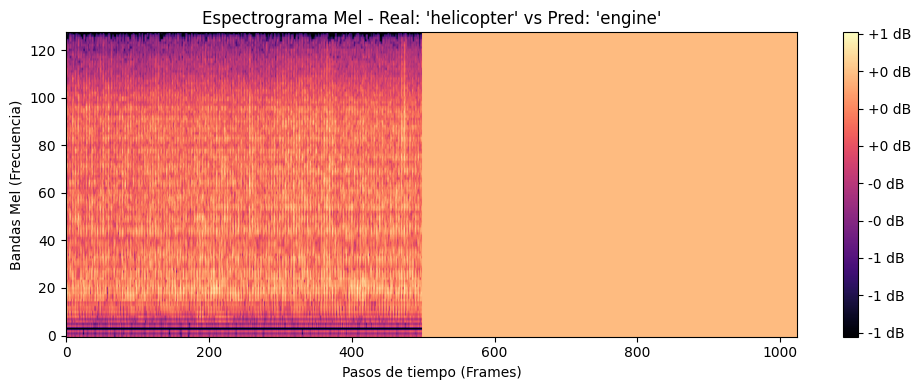

Muestra #54 | Estado: ❌ ERROR
Etiqueta Real:     footsteps
Predicción Modelo: fireworks (63.39%)
--------------------------------------------------
Top 3 Probabilidades:
  1. fireworks            -> 63.39%
  2. footsteps            -> 14.06%
  3. clapping             -> 2.59%


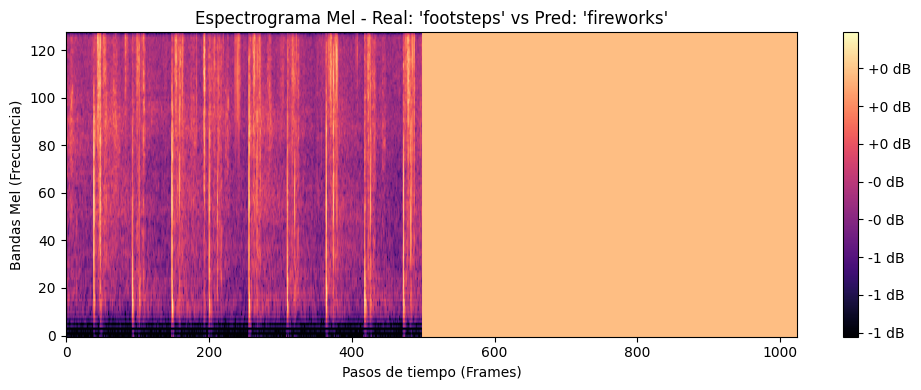

In [55]:
# Encontrar todos los índices del conjunto de prueba donde hubo error
y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(1)
indices_errores = np.where(y_true != y_pred)[0]

print(f"Total de errores encontrados: {len(indices_errores)} de {len(y_true)}")
print(f"Primeros 10 índices con error: {indices_errores[:10]}")

# Inspeccionar los primeros 3 errores de la lista
for idx in indices_errores[:3]:
    analisis_cualitativo(
        indice=int(idx),
        raw_ds=test_dataset,
        encoded_ds=encoded_test_ds,
        outputs=outputs,
        id2label=id2label,
    )

## Análisis cualitativo.

En los tres casos inspeccionados, la etiqueta real aparece siempre en el segundo lugar (Top-2) de probabilidades:

Muestra #41 (snoring vs. breathing): La probabilidad está muy repartida (breathing 27.67% frente a snoring 16.84%). El modelo no está "alucinando" una categoría ajena; detecta correctamente que es un sonido respiratorio humano cíclico, pero al ser un ronquido suave o con poca vibración gutural, la firma espectral se solapa con una respiración profunda.

Muestra #44 (helicopter vs. engine): Es prácticamente un empate técnico (engine 25.34% vs. helicopter 24.25%, con airplane en tercer lugar con 5.51%). Esto confirma exactamente el efecto "atractor" de engine observado en la matriz de confusión: si en el clip de audio el batido periódico de las aspas del helicóptero queda enmascarado por el ruido continuo de la turbina, el espectrograma resulta indistinguible del de un motor genérico.

2. Confusión por eventos transitorios e impulsivos (Alta confianza errónea)
Muestra #54 (footsteps vs. fireworks): A diferencia de los dos casos anteriores, aquí el modelo asigna una confianza alta a la clase incorrecta (fireworks con 63.39%, dejando a footsteps en segundo lugar con 14.06%).

Explicación acústica: Tanto las pisadas fuertes en superficies duras (o grava/hojas secas) como los fuegos artificiales lejanos generan impulsos secos de banda ancha (picos verticales repentinos en el espectrograma de Mel) seguidos de breves reverberaciones. Si el audio contiene ecos o pisadas irregulares y contundentes, el Transformer interpreta esos transitorios abruptos como detonaciones o estallidos (de hecho, la tercera opción es clapping, otro sonido puramente impulsivo).

En resumén, de los errores inspeccionados se encuentra que el modelo presenta:

1. Alta calibración de incertidumbre: En los errores más frecuentes (motores y sonidos humanos), el modelo muestra probabilidades bajas y muy cercanas entre las dos primeras opciones, lo que indica que reconoce la similitud acústica y sitúa la respuesta correcta inmediatamente detrás de la predicción principal (un Top-2 Accuracy sustancialmente superior al 93% de Top-1).

2. Limitación en la escala de energía y contexto semántico: Al normalizar los espectrogramas de entrada, se pierde la noción de volumen físico real (decibelios absolutos). Por ello, un evento cercano y de baja energía como una pisada (footsteps) puede presentar una envolvente espectral muy similar a un evento lejano y de alta energía como un fuego artificial (fireworks).

No se trata de una deficiencia del modelo, su calibración de incertidumbre (colocando la clase real en el Top-2 en los casos ambiguos) demuestra que aprendió representaciones acústicas sólidas, sino del techo natural impuesto por la ambigüedad física de los sonidos ambientales cuando se evalúan bajo un esquema de etiqueta única y con espectrogramas normalizados.